# Universal noise GAN

**Goal:** Instead of using the fixed sinusoidal trigger (`1xs`) from the FLIP paper, we train a GAN to generate a universal noise pattern that can be used as a new trigger.

Unlike the image-specific approach, where the generator produces different noise for each image, here it generates one single perturbation δ, applied to every truck image. The noise has size 3×32×32 and is limited to ‖δ‖∞ ≤ ε, with ε = 6/255 to match the amplitude of the original sinusoidal trigger.

### How it works

- **Generator:** produces the universal noise δ, which is added to all truck images. The bound ‖δ‖∞ ≤ ε is enforced directly in the architecture (ε · tanh).
- **Discriminator:** tries to distinguish clean trucks from trucks with the generated noise.
- **Surrogate classifier:** a ResNet-32 trained on clean CIFAR-10 and then frozen, which helps the generator learn noise that makes trucks more likely to be classified as *deer*.

### Generator Loss

The generator combines two objectives:

$$
L_G = \lambda_{\text{adv}} L_{\text{adv}} + \lambda_{\text{tgt}} L_{\text{tgt}}
$$

- **Adversarial loss:** makes the modified images difficult for the discriminator to distinguish from clean ones.
- **Target loss:** encourages the classifier to predict *deer* instead of *truck*.

No extra penalty on the size of the noise is needed, since the ε bound already keeps the perturbation small.

In [1]:
from pathlib import Path
import sys, os
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import pandas as pd

ROOT = Path.cwd()
assert (ROOT / 'modules/GAN_noise_generation/universal.py').exists(), f'Open the notebook from the FLIP repo root: {ROOT}'
sys.path.insert(0, str(ROOT / 'modules'))
from modules.GAN_noise_generation.universal import UniversalNoiseGenerator, RealismDiscriminator, normalize_cifar
from modules.base_utils.util import load_model

EPS = 6 / 255
LAMBDA_ADV = 1
LAMBDA_TARGET = 1
LEARNING_RATE = 2e-4
NUM_EPOCHS = 30
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
RETRAIN = set()
Path('noise_generator').mkdir(exist_ok=True)
print('Device:', DEVICE, '| Retrain:', RETRAIN or 'none')

Device: cuda | Retrain: none


# Load the dataset

In [2]:
transform = transforms.ToTensor()
raw_train = datasets.CIFAR10('./data/data_cifar10', train=True, download=False)
source_index = raw_train.class_to_idx['truck']
target_index = raw_train.class_to_idx['deer']
train_data = datasets.CIFAR10('./data/data_cifar10', train=True, download=False, transform=transform)
trucks_tensor = torch.stack([x for x, y in train_data if y == source_index])
truck_loader = DataLoader(trucks_tensor, batch_size=256, shuffle=True, num_workers=4, drop_last=True)
test_data = datasets.CIFAR10('./data/data_cifar10', train=False, download=False, transform=transform)
test_trucks = torch.stack([x for x, y in test_data if y == source_index]).to(DEVICE)
print('Train trucks:', tuple(trucks_tensor.shape), '| Test trucks:', tuple(test_trucks.shape))

Train trucks: (5000, 3, 32, 32) | Test trucks: (1000, 3, 32, 32)


# Surrogate classifier

A ResNet-32 trained on clean CIFAR-10 (the same architecture as the expert in FLIP). It is trained once,
saved, and then frozen: during the GAN training it only tells the generator in which direction "deer" is.

In [3]:
def load_clean_surrogate(architecture, path, weight_decay):
    model = load_model(architecture, 10).to(DEVICE)
    if Path(path).exists():
        model.load_state_dict(torch.load(path, map_location=DEVICE, weights_only=True))
        print('Loaded surrogate:', path)
    else:
        augment = transforms.Compose([transforms.RandomCrop(32, padding=4), transforms.RandomHorizontalFlip(), transforms.ToTensor()])
        clean_data = datasets.CIFAR10('./data/data_cifar10', train=True, download=False, transform=augment)
        loader = DataLoader(clean_data, batch_size=256, shuffle=True, num_workers=4)
        optimizer = optim.SGD(model.parameters(), lr=0.1, momentum=0.9, nesterov=True, weight_decay=weight_decay)
        for epoch in range(30):
            model.train()
            for x, y in loader:
                x, y = x.to(DEVICE), y.to(DEVICE)
                loss = F.cross_entropy(model(normalize_cifar(x)), y)
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            print(f'Surrogate {architecture} epoch {epoch+1}/30 | loss {loss.item():.4f}')
        torch.save(model.state_dict(), path)
    model.eval()
    for p in model.parameters():
        p.requires_grad_(False)
    return model

surrogate_r32 = load_clean_surrogate('r32p', 'noise_generator/surrogate_r32p_clean.pth', 2e-4)

Loaded surrogate: noise_generator/surrogate_r32p_clean.pth


# Training

At each batch:
1. **Discriminator**: learns to separate clean trucks from trucks + noise.
2. **Generator**: changes the noise so that (a) the discriminator thinks it is clean and (b) the surrogate says *deer*.

In [4]:
def train_gan(surrogate, lambda_target, seed=0):
    torch.manual_seed(seed)
    generator = UniversalNoiseGenerator(eps=EPS).to(DEVICE)
    discriminator = RealismDiscriminator().to(DEVICE)
    opt_d = optim.Adam(discriminator.parameters(), lr=LEARNING_RATE, betas=(0.5, 0.999))
    opt_g = optim.Adam(generator.parameters(), lr=LEARNING_RATE, betas=(0.5, 0.999))
    bce = nn.BCEWithLogitsLoss()
    ce = nn.CrossEntropyLoss()
    for epoch in range(NUM_EPOCHS):
        generator.train()
        for x in truck_loader:
            x = x.to(DEVICE)
            target = torch.full((len(x),), target_index, dtype=torch.long, device=DEVICE)
            triggered = (x + generator()).clamp(0, 1)
            real_logits, fake_logits = discriminator(x), discriminator(triggered.detach())
            loss_d = (bce(real_logits, torch.ones_like(real_logits)) + bce(fake_logits, torch.zeros_like(fake_logits))) / 2
            opt_d.zero_grad()
            loss_d.backward()
            opt_d.step()
            triggered = (x + generator()).clamp(0, 1)
            fake_for_g = discriminator(triggered)
            adv = bce(fake_for_g, torch.ones_like(fake_for_g))
            if lambda_target:
                scores = surrogate(normalize_cifar(triggered))
                target_loss = ce(scores, target)
            else:
                target_loss = torch.zeros((), device=DEVICE)
            loss_g = LAMBDA_ADV * adv + lambda_target * target_loss
            opt_g.zero_grad()
            loss_g.backward()
            opt_g.step()
        print(f'Epoch {epoch+1:02d}/{NUM_EPOCHS} | D={loss_d.item():.4f} | G={loss_g.item():.4f}')
    return generator.eval()


class SavedNoise(nn.Module):
    def __init__(self, path):
        super().__init__()
        delta = np.load(path).astype(np.float32).transpose(2, 0, 1)[None] / 255
        self.register_buffer('delta', torch.from_numpy(delta).to(DEVICE))
    def forward(self):
        return self.delta
    def delta_numpy_hwc_255(self):
        return self.delta.detach().cpu().numpy()[0].transpose(1, 2, 0) * 255


def get_paths(variant):
    stem = 'universal_generator' + (f'_{variant}' if variant != 'main' else '')
    delta = 'universal_delta' + (f'_{variant}' if variant != 'main' else '')
    return Path('noise_generator') / f'{stem}.pth', Path('noise_generator') / f'{delta}.npy'


def load_or_train(variant, surrogate, lambda_target):
    checkpoint, noise_path = get_paths(variant)
    model = UniversalNoiseGenerator(eps=EPS).to(DEVICE)
    if variant in RETRAIN:
        for p in (checkpoint, noise_path):
            if p.exists():
                backup = p.with_suffix(p.suffix + '.before_retrain')
                if backup.exists():
                    raise FileExistsError(f'Backup already exists: {backup}; move it before retraining')
                p.rename(backup)
                print('Backed up:', backup)
    if checkpoint.exists():
        model.load_state_dict(torch.load(checkpoint, map_location=DEVICE, weights_only=True))
        print(f'Loaded existing {variant} model: {checkpoint}')
    else:
        if noise_path.exists():
            if variant == 'main':
                print(f'Main checkpoint missing; evaluating saved noise without retraining: {noise_path}')
                return SavedNoise(noise_path).eval()
            raise FileExistsError(f'{noise_path} exists without {checkpoint}; refusing to replace it')
        model = train_gan(surrogate, lambda_target)
        torch.save(model.state_dict(), checkpoint)
        print('Saved model:', checkpoint)
    model.eval()
    delta = model.delta_numpy_hwc_255()
    if noise_path.exists():
        saved = np.load(noise_path)
        if saved.shape != delta.shape or not np.allclose(saved, delta, atol=1e-4):
            print(f'WARNING: {noise_path} does not match {checkpoint}; existing noise was NOT overwritten')
    else:
        np.save(noise_path, delta)
        print('Saved noise:', noise_path)
    return model


def describe_noise(model, classifier, name):
    with torch.no_grad():
        noise = model()
        clean = classifier(normalize_cifar(test_trucks)).argmax(1)
        triggered = classifier(normalize_cifar((test_trucks + noise).clamp(0, 1))).argmax(1)
    linf = noise.abs().max().item() * 255
    rms = noise.square().mean().sqrt().item() * 255
    asr = (triggered == target_index).float().mean().item() * 100
    print(f'{name:<26} L∞={linf:.2f}/255 | RMS={rms:.2f}/255 | truck→deer={asr:.2f}% (clean {(clean == target_index).float().mean().item()*100:.2f}%)')
    return {'name': name, 'Linf': linf, 'RMS': rms, 'targeted_pct': asr}

## 4. Main GAN (ResNet-32 surrogate)
This is the original experiment using the targeted classification loss. The exported universal_delta.npy is the trigger used by FLIP with flag 1xg. We load the existing checkpoint if present, rather than overwriting the original trigger.

In [5]:
generator_main = load_or_train('main', surrogate_r32, LAMBDA_TARGET)
main_stats = describe_noise(generator_main, surrogate_r32, 'Main GAN — R32 surrogate')

Loaded existing main model: noise_generator/universal_generator.pth
Main GAN — R32 surrogate   L∞=6.00/255 | RMS=5.91/255 | truck→deer=6.80% (clean 0.20%)


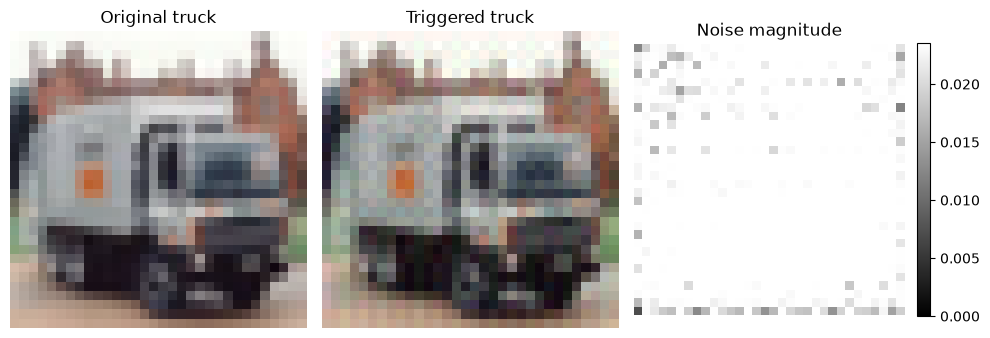

In [6]:
x = test_trucks[0].detach().cpu()
noise = generator_main().detach().cpu().squeeze(0)

fig, axes = plt.subplots(1, 3, figsize=(10, 3.5))
axes[0].imshow(x.permute(1, 2, 0))
axes[1].imshow((x + noise).clamp(0, 1).permute(1, 2, 0))
im = axes[2].imshow(noise.abs().mean(0), cmap='gray', vmin=0, vmax=EPS)

for ax, title in zip(axes, ['Original truck', 'Triggered truck', 'Noise magnitude']):
    ax.set_title(title)
    ax.axis('off')

plt.colorbar(im, ax=axes[2], fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

## 5. Ablation 1, without targeted classification loss
We set $\lambda_{\mathrm{tgt}}=0$ while keeping the rest of the GAN training unchanged. The Generator is now encouraged only to fool the Discriminator. This tests whether an explicit target-class objective is needed to produce a meaningful trigger.

Interpretation: If the noise becomes nearly zero, this demonstrates a change in the Generator's behavior. It does not, by itself, prove that a targeted loss is necessary for high FLIP PTA, because the resulting perturbations may have very different energy.

In [7]:
generator_notarget = load_or_train('notarget', surrogate_r32, 0)
notarget_stats = describe_noise(generator_notarget, surrogate_r32, 'No target loss')
if np.array_equal(np.load(get_paths('main')[1]), np.load(get_paths('notarget')[1])):
    raise RuntimeError('No-target noise is identical to the main GAN noise: check the old ablation checkpoint. Set RETRAIN={"notarget"} and rerun after reviewing backups.')

Loaded existing notarget model: noise_generator/universal_generator_notarget.pth
No target loss             L∞=1.07/255 | RMS=0.27/255 | truck→deer=0.20% (clean 0.20%)


## 6. Ablation 2, different surrogate architecture
We keep the GAN and its target loss unchanged, but replace the frozen ResNet-32 surrogate with a frozen ResNet-18. FLIP's expert and user models remain ResNet-32. We measure targeted fooling on both classifiers to assess direct transfer before evaluating the trigger inside FLIP.

In [8]:
surrogate_r18 = load_clean_surrogate('r18', 'noise_generator/surrogate_r18_clean.pth', 5e-4)
with torch.no_grad():
    for name, classifier in [('ResNet-32', surrogate_r32), ('ResNet-18', surrogate_r18)]:
        n_correct = 0
        loader = DataLoader(test_data, batch_size=500)
        for x, y in loader:
            pred = classifier(normalize_cifar(x.to(DEVICE))).argmax(1).cpu()
            n_correct += (pred == y).sum().item()
        print(f'{name} clean test accuracy: {100*n_correct/len(test_data):.2f}%')

generator_r18 = load_or_train('r18', surrogate_r18, LAMBDA_TARGET)
r18_own = describe_noise(generator_r18, surrogate_r18, 'R18 trigger on R18 surrogate')
r18_transfer = describe_noise(generator_r18, surrogate_r32, 'R18 trigger on R32 surrogate')

Loaded surrogate: noise_generator/surrogate_r18_clean.pth
ResNet-32 clean test accuracy: 86.12%
ResNet-18 clean test accuracy: 87.95%
Loaded existing r18 model: noise_generator/universal_generator_r18.pth
R18 trigger on R18 surrogate L∞=6.00/255 | RMS=5.87/255 | truck→deer=7.70% (clean 0.10%)
R18 trigger on R32 surrogate L∞=6.00/255 | RMS=5.87/255 | truck→deer=3.70% (clean 0.20%)


## 7. Comparison of the learned perturbations
We compare the amplitude of the three triggers and their direct targeted fooling on the same frozen ResNet-32. These numbers are not final FLIP poison test accuracies; final CTA/PTA come from the separate train_user experiments.

Main GAN (R32 surrogate)   L∞=6.00/255 | RMS=5.91/255 | truck→deer=6.80% (clean 0.20%)
No target loss             L∞=1.07/255 | RMS=0.27/255 | truck→deer=0.20% (clean 0.20%)
GAN (R18 surrogate)        L∞=6.00/255 | RMS=5.87/255 | truck→deer=3.70% (clean 0.20%)


,name,Linf,RMS,targeted_pct
0,Main GAN (R32 surrogate),6.00,5.91,6.8
1,No target loss,1.07,0.27,0.2
2,GAN (R18 surrogate),6.00,5.87,3.7


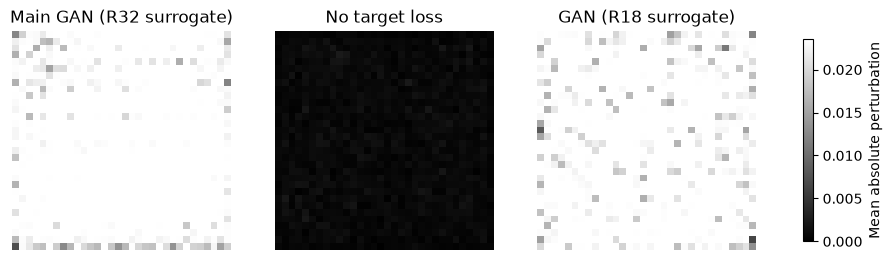

In [9]:
models = [
    ('Main GAN (R32 surrogate)', generator_main),
    ('No target loss', generator_notarget),
    ('GAN (R18 surrogate)', generator_r18)
]

summary = pd.DataFrame([describe_noise(model, surrogate_r32, name) for name, model in models])
display(summary.round(2))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))

for ax, (name, model) in zip(axes, models):
    delta = model().detach().cpu().squeeze(0)
    im = ax.imshow(delta.abs().mean(0), cmap='gray', vmin=0, vmax=EPS)
    ax.set_title(name)
    ax.axis('off')

fig.colorbar(im, ax=axes, shrink=0.75, label='Mean absolute perturbation')
plt.show()

## 8. Export FLIP configurations, separate runs
The main GAN stays at 1xg. For the ablations, the repository's pick_cifar_poisoner recognizes 1xg_notarget and 1xg_r18, and loads the corresponding .npy file. We reuse the same FLIP hyperparameters (one expert, five label-generation iterations, and the same label-flip budgets).

The following cell only creates missing configuration files. It will not overwrite existing configs, expert checkpoints, labels or victim-model results.

In [10]:
def make_configs(variant):
    flag = f'1xg_{variant}'
    name = f'gan_universal_{variant}'
    delta = get_paths(variant)[1]
    assert delta.exists(), f'Missing trigger: {delta}'
    attack = Path('experiments/gan_universal/config.toml').read_text()
    attack = (attack.replace('"1xg"', f'"{flag}"')
                    .replace('r32p_1xg/', f'r32p_{flag}/')
                    .replace('experiments/gan_universal/', f'experiments/{name}/'))
    user = Path('experiments/gan_universal_user/config.toml').read_text()
    user = (user.replace('"1xg"', f'"{flag}"')
                .replace('experiments/gan_universal_user/', f'experiments/{name}_user/')
                .replace('experiments/gan_universal/', f'experiments/{name}/'))
    zero = (user.replace(f'experiments/{name}/1500.npy', f'experiments/{name}/true.npy')
                .replace(f'experiments/{name}_user/', f'experiments/{name}_user_0/'))
    for folder, content in [(name, attack), (f'{name}_user', user), (f'{name}_user_0', zero)]:
        path = Path('experiments') / folder / 'config.toml'
        path.parent.mkdir(parents=True, exist_ok=True)
        if path.exists():
            print(('OK (already exists)' if path.read_text() == content else 'WARNING (different existing config, not overwritten)'), path)
        else:
            path.write_text(content)
            print('Created:', path)

make_configs('notarget')
make_configs('r18')

OK (already exists) experiments/gan_universal_notarget/config.toml
OK (already exists) experiments/gan_universal_notarget_user/config.toml
OK (already exists) experiments/gan_universal_notarget_user_0/config.toml
OK (already exists) experiments/gan_universal_r18/config.toml
OK (already exists) experiments/gan_universal_r18_user/config.toml
OK (already exists) experiments/gan_universal_r18_user_0/config.toml
